In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import numdifftools as nd
from scipy import stats
from scipy.optimize import minimize
from scipy.optimize import approx_fprime

import importlib
import SyntheticPhaseNonlinearMeasurement as SPNM
importlib.reload(SPNM)

%config InlineBackend.figure_format = 'retina'
cmap = plt.cm.viridis
rng = np.random.default_rng(seed=326890)   # PCG64 by default

# Model
## Phase drift and diffusion with measurement noise

The unwrapped phase evolves according to the discrete-time stochastic process
\begin{equation}
    \theta_{k+1}
    = \theta_k + \omega \Delta t + \varepsilon_k,
    \qquad
    \varepsilon_k \sim \mathcal{N}(0, 2 D_\theta \Delta t),
\end{equation}
for $k = 1,\dots,N-1$.
The parameters are $\lambda = \{\omega, D_\theta, R\}$.
In contrast to the linear observation model of Example 1a, the phase is now observed indirectly through a nonlinear mapping to the unit circle.
The measurement at time $t_k$ is a two-dimensional vector
\begin{equation}
    \mathbf y_k =
    \begin{bmatrix}
    y_{1k} \\
    y_{2k}
    \end{bmatrix}
    =
    \begin{bmatrix}
    \cos \theta_k \\
    \sin \theta_k
    \end{bmatrix}
    + \boldsymbol\eta_k,
    \qquad
    \boldsymbol\eta_k \sim \mathcal{N}(\mathbf 0, R \mathbf I_2).
\end{equation}
Equivalently, defining the observation function
\begin{equation}
    \mathbf h(\theta) =
    \begin{bmatrix}
    \cos \theta \\
    \sin \theta
    \end{bmatrix},
\end{equation}
the measurement model may be written compactly as
\begin{equation}
    \mathbf y_k = \mathbf h(\theta_k) + \boldsymbol\eta_k.
\end{equation}
The observation noise is assumed isotropic with variance $R$ per component.

### Simulated data

We can simulate data from this model as follows.

In [2]:
rng = np.random.default_rng(seed=326890)   # PCG64 by default
N = 1000 # number of data points
dt = 0.05 # time step, seconds

omega = 1.   # drift velocity
Dtheta = 0.1 # diffusion coefficient 
R = 0.001    # noise variance, radians^2
param = (omega,Dtheta,R)

mu_theta = 0
sigma_theta = 2*np.pi
state_priors = (mu_theta, sigma_theta)

## Simulate unwrapped phase data
tk, thetak, yk = SPNM.simulate_data(param, N, dt, rng, state_priors)

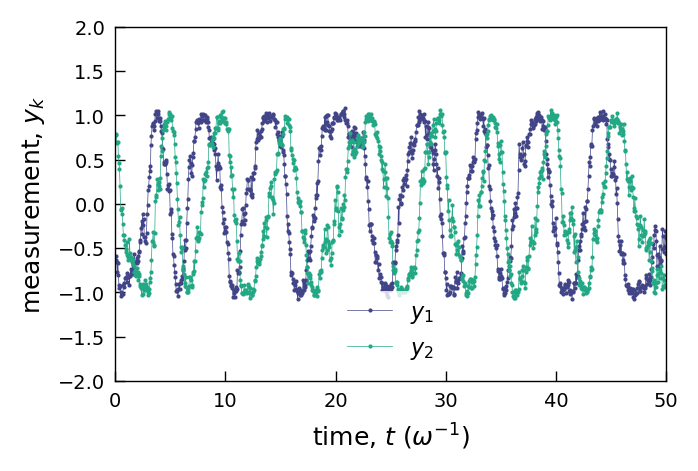

In [3]:
# Desired axes dimensions in centimeters
axes_width_cm = 7
axes_height_cm = 4.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
ax.plot(tk, yk[:,0], '.-', lw=0.25, mew=0, ms=3, color=cmap(0.2), label='$y_1$')
ax.plot(tk, yk[:,1], '.-', lw=0.25, mew=0, ms=3, color=cmap(0.6), label='$y_2$')
# ax.plot(tk, np.mod(thetak,2*np.pi), '.', ms=2, mew=0, label=r'unobserved, $\theta_k$', color=cmap(0.2))
# ax.plot(tk, np.mod(yk,2*np.pi), '.', ms=2, mew=0, label='measured, $y_k$', color=cmap(0.6))

# Set axis labels with font size 9 pt
ax.set_xlabel(r'time, $t$ ($\omega^{-1}$)', fontsize=9)
ax.set_ylabel(r'measurement, $y_k$', fontsize=9)

# Create legend (frame turned off)
ax.legend(frameon=True, edgecolor='none', fontsize=8)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')


# Set the x-axis limits from 0 to 2000
ax.set_xlim(0, N*dt)
ax.set_ylim(-2, 2)

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/SyntheticPhaseTrace.pdf')

In [4]:
list_of_tuples = list(zip(tk,yk,thetak))
df = pd.DataFrame(list_of_tuples,
                  columns=['t', 'y', 'theta'])
df

,t,y,theta
0,0.05,"[-0.6395315723034211, 0.7885346192005763]",-4.006215
1,0.10,"[-0.5846679024313862, 0.7751858815865542]",-4.078021
2,0.15,"[-0.6535720082503885, 0.692700500076195]",-3.987084
3,0.20,"[-0.7724730285308, 0.6812300060457174]",-3.891844
4,0.25,"[-0.668980804781152, 0.700642621204937]",-3.956723
...,...,...,...
995,49.80,"[-0.5436263246803833, -0.8068759814003681]",48.175424
996,49.85,"[-0.4724049723481771, -0.9327279189497047]",48.252744
997,49.90,"[-0.30642615374513477, -0.9410569626469437]",48.364670
998,49.95,"[-0.38346569471437153, -0.9279748315280041]",48.294892


In [5]:
df.to_csv('plots/simulated_data_SP.csv',index=False)

### Estimate frequency

In [8]:
data = (tk, yk)
omega_FFT, _ , _ = SPNM.estimate_frequency_fft(data)
print(f'Frequency estimate = {omega_FFT:.5f}')

Frequency estimate = 1.00531


### Estimate initial phase

In [9]:
R_est = R            # we just need a crude estimate of the noise variance here
window_size = 6      # select the window used for initialization
phase_init = SPNM.estimate_initial_phase_regression(data, omega_FFT, window_size, R_est)

print("phi =", phase_init["phi_mean"])
print("sigma_phi =", phase_init["phi_std"])
print("A =", phase_init["A_mean"])
print("B =", phase_init["B_mean"])
print("radius =", phase_init["radius_mean"], "+/-", phase_init["radius_std"])
print("consistent with 1?", phase_init["radius_consistent"])

phi = 2.1735699967736126
sigma_phi = 0.013135691242598144
A = -0.557186396200295
B = 0.8096092653187982
radius = 0.9828142462341072 +/- 0.012909944487358056
consistent with 1? True


In [10]:
mu_theta = phase_init["phi_mean"] + omega_FFT * tk[0]
sigma_theta = 2 * phase_init["phi_std"] # inflate by 2 to be cautious
state_priors = (mu_theta, sigma_theta)

#  Estimating latent phase, $p(\theta_{1:N} \mid y_{1:N}, \lambda)$

Given the parameters $\lambda=\{\omega,  D_\theta, R\}$ and the observed data $y_{1:N}=\{y_1,\dots,y_N\}$, we seek to infer the phase $\theta_{1:N}=\{\theta_1,\dots,\theta_N\}$ using a [Kalman filter](https://en.wikipedia.org/wiki/Kalman_filter)<sup id="fn1">[1](#f1)</sup> with Rauch-Tung-Striebel smoothing.<sup id="fn2">[2](#f2)</sup> This algorithm provides an efficient approach that scales linearly with the number of time steps $N$.

<p id="f1"><b>[1]</b> Kalman, R. E. (1960). "A New Approach to Linear Filtering and Prediction Problems". Journal of Basic Engineering. 82: 35–45. doi:10.1115/1.3662552.</p>
<p id="f2"><b>[2]</b> Rauch, H.E.; Tung, F.; Striebel, C. T. (August 1965). "Maximum likelihood estimates of linear dynamic systems". AIAA Journal. 3 (8): 1445–1450. doi:10.2514/3.3166.</p>


### Priors $p(\lambda)$

\begin{equation}
\begin{aligned}
    \theta_0 &\sim \mathcal{N}( \mu_\theta, \sigma^2_\theta )
    \\
    \omega &\sim \mathcal{N}( \mu_\omega, \sigma^2_\omega )
\end{aligned}
\qquad
\begin{aligned}
    D_\theta &\sim \mathrm{Inv\text{-}Gamma}(\alpha_D, \beta_D)
    \\
    R &\sim \mathrm{Inv\text{-}Gamma}(\alpha_R, \beta_R)
\end{aligned}
\end{equation}

In [11]:
# parameter priors 
mu_omega = omega
sigma_omega = omega
alpha_D = 2.0            # Laplace variance 1/alpha
beta_D = alpha_D*Dtheta  # mode = alpha/beta for log parameterization
alpha_R = 2.0            # Laplace variance 1/alpha
beta_R = alpha_R*R       # mode = alpha/beta for log parameterization

param_priors = (mu_omega, sigma_omega, alpha_D, beta_D, alpha_R, beta_R)
priors = state_priors + param_priors

## Forward Kalman Filter

In [12]:
# Kalman filter
param = (omega, Dtheta, R)
data = (tk, yk)
thetakk, Pkk, thetakk_1, Pkk_1, ypred, Hk, ck = SPNM.kalman_filter(param, data, state_priors)

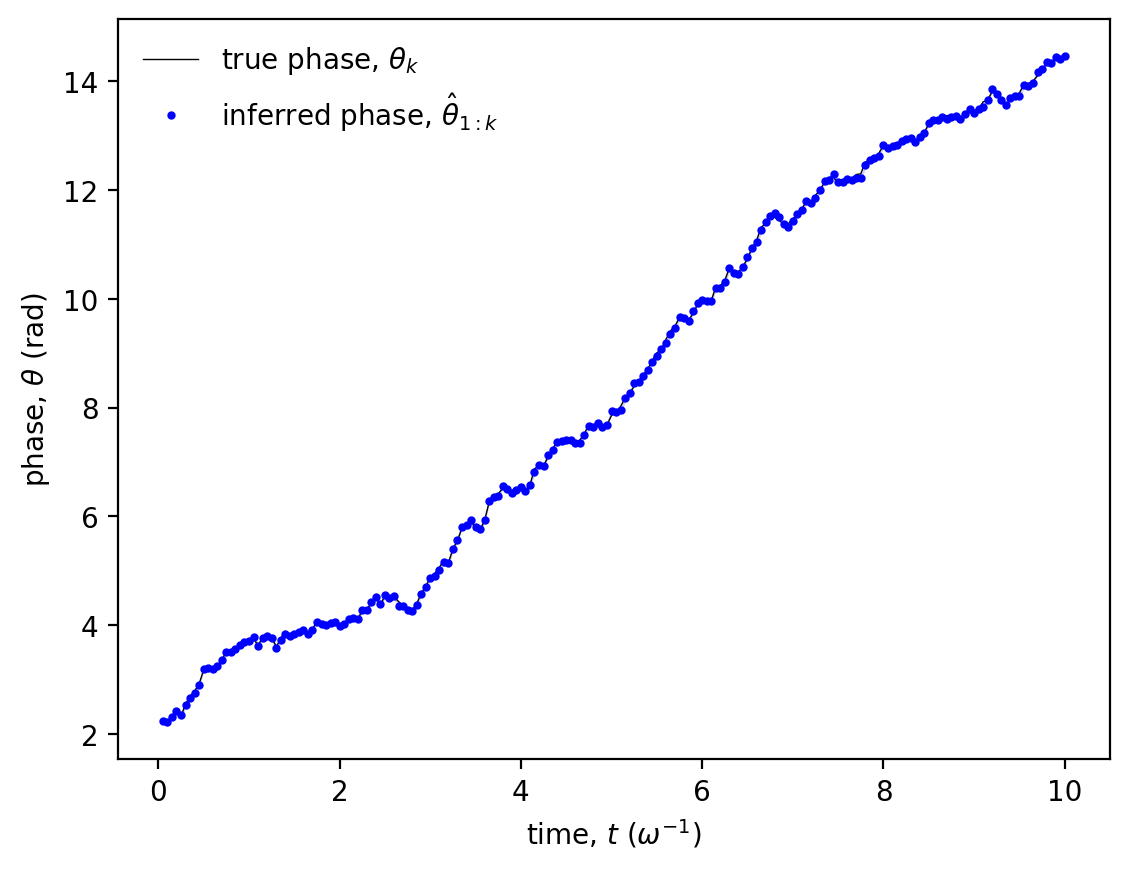

In [13]:
kmax = 200
plt.plot(tk[:kmax], 2*np.pi + thetak[:kmax], '-', c='k', lw=0.5, label=r'true phase, $\theta_k$')
plt.plot(tk[:kmax], thetakk[:kmax], '.', c='b', ms=4, label=r'inferred phase, $\hat{\theta}_{1:k}$')
plt.fill_between(tk[:kmax], thetakk[:kmax] + 1.96*np.sqrt(Pkk[:kmax]), thetakk[:kmax] - 1.96*np.sqrt(Pkk[:kmax]), 
                 color='b', alpha=0.2, lw=0);

plt.xlabel(r'time, $t$ ($\omega^{-1}$)')
plt.ylabel(r'phase, $\theta$ (rad)')
plt.legend(frameon=False);

We can compute $\log p(y_{1:N}\mid \lambda)$ from the Kalman filter.

In [14]:
nlml = SPNM.neg_log_marginal_likelihood(param, data, state_priors, param_mode="natural")
print(f'Negative log marginal likelihood: {nlml:.5}')

log_param = (omega, np.log(Dtheta), np.log(R))
nlml = SPNM.neg_log_marginal_likelihood(log_param, data, state_priors, param_mode="log")
print(f'Negative log marginal likelihood: {nlml:.5}')

Negative log marginal likelihood: -2777.3
Negative log marginal likelihood: -2777.3


## Backward Rauch-Tung-Striebel (RTS) Smoother

In [15]:
kalman_phases = (thetakk, Pkk, thetakk_1, Pkk_1)
thetakN, PkN, Sigmakk_1 = SPNM.rts_smoother(param, data, kalman_phases)

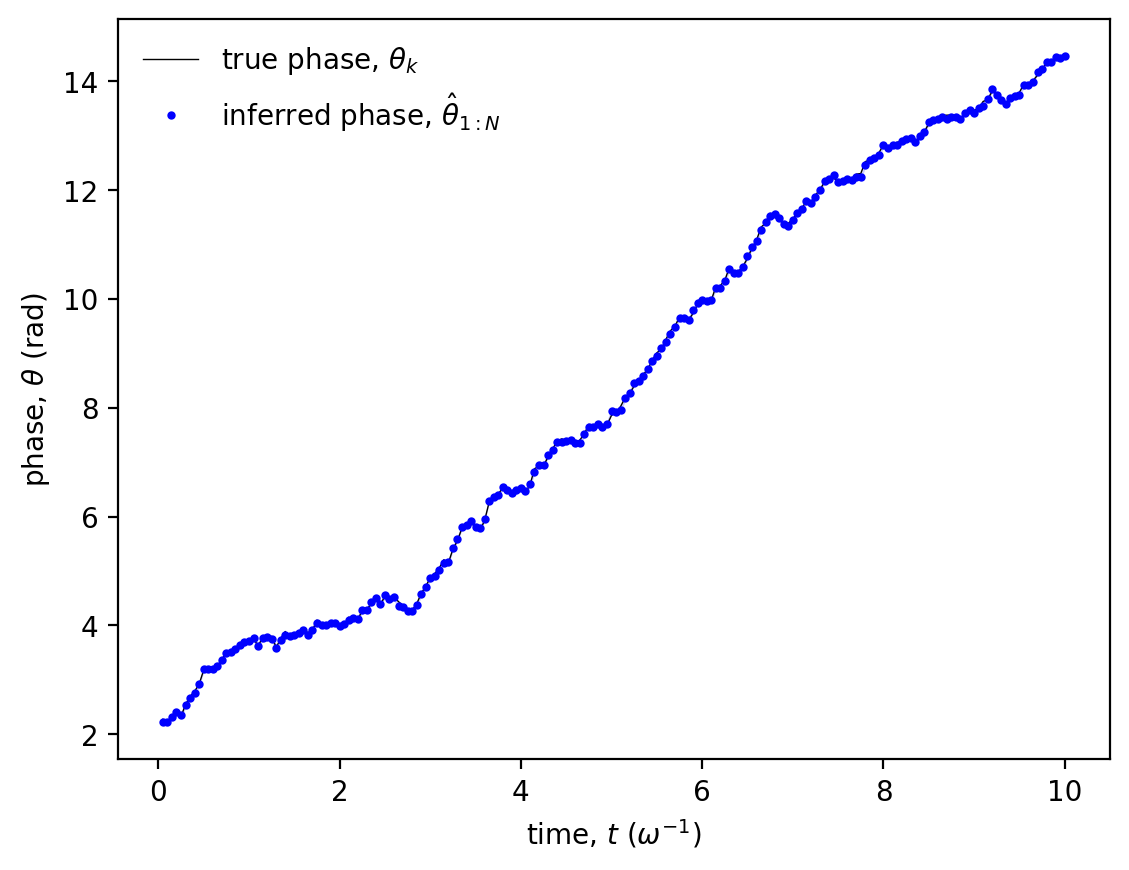

In [16]:
kmax = 200
plt.plot(tk[:kmax], 2*np.pi + thetak[:kmax], '-', c='k', lw=0.5, label=r'true phase, $\theta_k$')
plt.plot(tk[:kmax], thetakN[:kmax], '.', c='b', ms=4, label=r'inferred phase, $\hat{\theta}_{1:N}$')
plt.fill_between(tk[:kmax], thetakN[:kmax] + 1.96*np.sqrt(PkN[:kmax]), thetakN[:kmax] - 1.96*np.sqrt(PkN[:kmax]), 
                 color='b', alpha=0.2, lw=0);

plt.xlabel(r'time, $t$ ($\omega^{-1}$)')
plt.ylabel(r'phase, $\theta$ (rad)')
plt.legend(frameon=False);

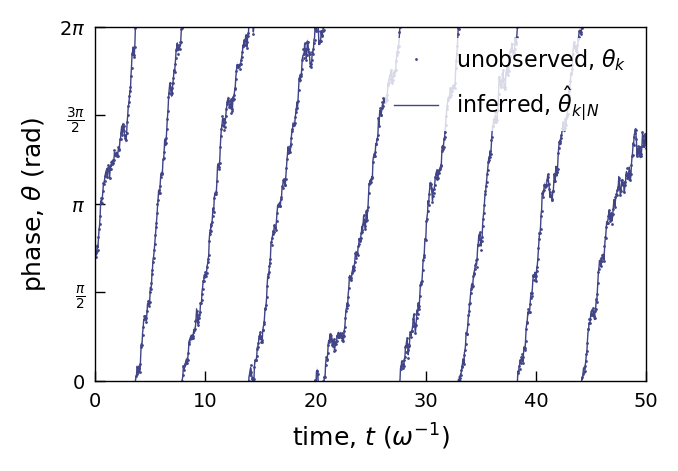

In [18]:
# Desired axes dimensions in centimeters
axes_width_cm = 7
axes_height_cm = 4.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
ax.plot(tk, np.mod(thetak, 2*np.pi), '.', ms=2, mew=0, label=r'unobserved, $\theta_k$', color=cmap(0.2))
ax.plot(tk, thetakN + 2*np.pi, '-', lw=0.5, label=r'inferred, $\hat{\theta}_{k|N}$', color=cmap(0.2))

thetakN_upper = thetakN + 1.96*np.sqrt(PkN)
thetakN_lower = thetakN - 1.96*np.sqrt(PkN)
ax.fill_between(tk, thetakN_upper + 2*np.pi, thetakN_lower + 2*np.pi, color=cmap(0.2), alpha=0.2, lw=0);

for i in range(0,9):
    ax.plot(tk, thetakN - i*2*np.pi, '-', lw=0.5, color=cmap(0.2))
    ax.fill_between(tk, thetakN_upper - i*2*np.pi, thetakN_lower - i*2*np.pi, color=cmap(0.2), alpha=0.2, lw=0);


# Set axis labels with font size 9 pt
ax.set_xlabel(r'time, $t$ ($\omega^{-1}$)', fontsize=9)
ax.set_ylabel(r'phase, $\theta$ (rad)', fontsize=9)

# Create legend (frame turned off)
ax.legend(frameon=True, fontsize=8, edgecolor='none', loc=1)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

ax.set_yticks([0,
               np.pi/2,
               np.pi,
               3*np.pi/2,
               2*np.pi])

ax.set_yticklabels([r'$0$',
                    r'$\frac{\pi}{2}$',
                    r'$\pi$',
                    r'$\frac{3\pi}{2}$',
                    r'$2\pi$'])

ax.set_xlim(0, N*dt)
ax.set_ylim(0, 2*np.pi)

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/SyntheticPhaseTrace_Inferred.pdf')

## Mean Squared Displacement (revisited)

In [19]:
# Solve Ax = rhs
Sigma = SPNM.theta_covariance(param, N, dt, state_priors)

The diagonal entries are the same as those obtained from the Kalman filter above.

In [20]:
error = np.array([np.linalg.norm(Sigma[k,k] - PkN[k]) for k in range(N)])
print(error.mean())

1.6604556271615501e-19


We can compute the relevant elements in a more efficient way as follows.

In [21]:
error = np.array([(Sigma[k,k-1]-Sigmakk_1[k]) for k in range(1,N)])
print(error.mean())

-1.835492416632742e-20


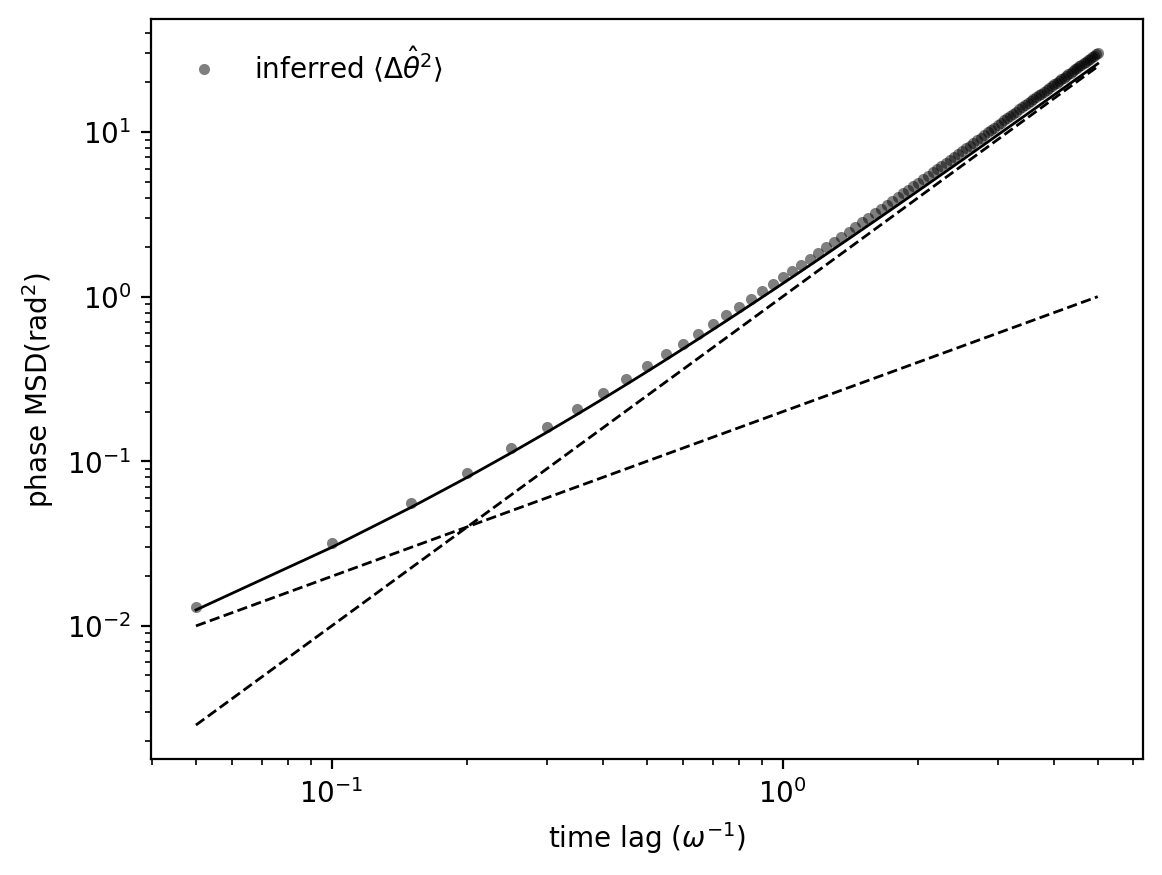

In [22]:
lags = 1+np.arange(100)
thetahat_msds = np.zeros(lags.shape)     # non-overlapping
thetahat_msds_ol = np.zeros(lags.shape)  # overlapping

for i,lag in enumerate(lags):
    thetahat_msds[i] = np.mean((thetakN[lag::lag] - thetakN[:-lag:lag])**2 + np.diag(Sigma)[lag::lag] + np.diag(Sigma)[:-lag:lag]
                           - 2*np.diag(Sigma,k=lag)[::lag])  # non-overlapping
    thetahat_msds_ol[i] = np.mean((thetakN[lag:] - thetakN[:-lag])**2 + np.diag(Sigma)[lag:] + np.diag(Sigma)[:-lag]
                           - 2*np.diag(Sigma,k=lag))         # overlapping
    
# plt.loglog(dt*lags, thetahat_msds, 'ko', mew=0, ms=4, alpha=0.5, label=r'inferred $\langle \Delta x^2 \rangle$')
plt.loglog(dt*lags, thetahat_msds_ol, 'ko', mew=0, ms=4, alpha=0.5, label=r'inferred $\langle \Delta \hat{\theta}^2 \rangle$')


plt.plot(dt * lags, 2 * Dtheta * dt * lags + (omega * dt * lags)**2, 'k-', lw=1)
plt.plot(dt * lags, (omega * dt * lags)**2, 'k--', lw=1)
plt.plot(dt * lags, 2 * Dtheta * dt * lags, 'k--', lw=1)

plt.ylabel(r'phase MSD(rad$^2$)')
plt.xlabel(r'time lag ($\omega^{-1}$)')
plt.legend(frameon=False);

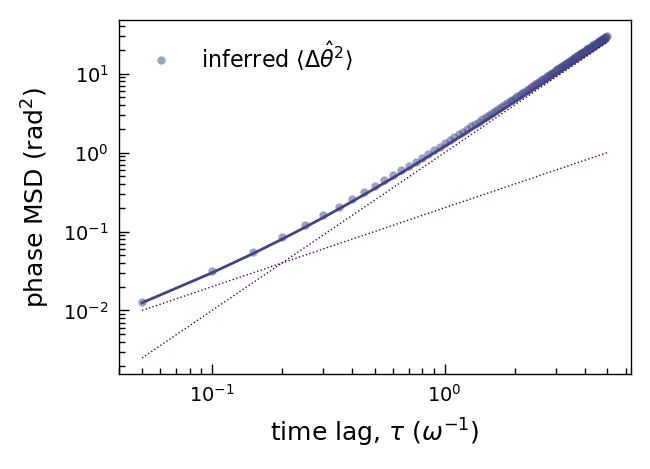

In [23]:
# Desired axes dimensions in centimeters
axes_width_cm = 6.5
axes_height_cm = 4.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
# ax.loglog(dt*lags, thetahat_msds, 'o', mew=0, ms=3, color=cmap(0.2), alpha=0.5, 
# label=r'inferred $\langle \Delta \hat{\theta}^2 \rangle$')
ax.loglog(dt*lags, thetahat_msds_ol,  'o', mew=0, ms=3, color=cmap(0.2), alpha=0.5, 
          label=r'inferred $\langle \Delta \hat{\theta}^2 \rangle$')
ax.plot(dt*lags, 2*Dtheta*dt*lags +  (omega*dt*lags)**2, '-', lw=1, color=cmap(0.2))

# Theory
ax.plot(dt*lags, (omega*dt*lags)**2, ':', lw=0.5, color=cmap(0))
ax.plot(dt*lags, 2*Dtheta*dt*lags, ':', lw=0.5, color=cmap(0))

# Set axis labels with font size 9 pt
ax.set_xlabel(r'time lag, $\tau$ ($\omega^{-1}$)', fontsize=9)
ax.set_ylabel(r'phase MSD (rad$^2$)', fontsize=9)

# Create legend (frame turned off)
ax.legend(frameon=False, fontsize=8)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/SyntheticPhaseMSD.pdf')

# Estimating parameters, $p(\lambda \mid y_{1:N})$

## Optimization of $\log p(\lambda \mid y)$ 

### Gradient-free optimizer

We can optimize $-\log p(\lambda\mid y)$ directly using a gradient free optimizer like Powell or Nelder-Mead.

In [24]:
%%time

res = minimize(
    fun=lambda x: SPNM.neg_log_posterior(x, data, priors, param_mode="log"),
    x0=log_param,
    method="Powell")

lambda_map = res.x
print(res,'\n')

 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: -2793.4851500170334
       x: [ 1.026e+00 -2.277e+00 -6.835e+00]
     nit: 2
   direc: [[ 1.000e+00  0.000e+00  0.000e+00]
           [ 0.000e+00  1.000e+00  0.000e+00]
           [ 0.000e+00  0.000e+00  1.000e+00]]
    nfev: 58 

CPU times: user 929 ms, sys: 5.37 ms, total: 934 ms
Wall time: 937 ms


### Finite difference hessian

In [25]:
%%time

## Compute the hessian matrix
f = lambda x: SPNM.neg_log_posterior(x, data, priors, param_mode="log")
hessFunc = nd.Hessian(f)
lambda_hess = hessFunc(lambda_map)
lambda_cov = np.linalg.inv(lambda_hess)

## Print parameter estimates
print(f'omega\t= {lambda_map[0]:.5f} +/- {np.sqrt(lambda_cov[0,0]):.5f}' )
print(f'Dtheta\t= {np.exp(lambda_map[1]):.5f} * exp(+/- {np.sqrt(lambda_cov[1,1]):.5f})' )
print(f'R\t= {np.exp(lambda_map[2]):.5f} * exp(+/- {np.sqrt(lambda_cov[2,2]):.5f})\n' )

omega	= 1.02640 +/- 0.05881
Dtheta	= 0.10256 * exp(+/- 0.05301)
R	= 0.00108 * exp(+/- 0.04410)

CPU times: user 4.15 s, sys: 16.9 ms, total: 4.17 s
Wall time: 4.24 s


### Marginal Distributions

z-score: 0.44895


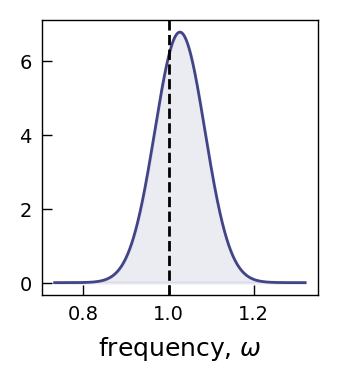

In [26]:
omega_map = lambda_map[0]
omega_err = np.sqrt(lambda_cov[0,0])
print(f'z-score: {(omega_map-omega)/omega_err:.5}')

x = np.linspace(omega_map-5*omega_err, omega_map+5*omega_err, 500)
pdf = stats.norm.pdf(x, loc=omega_map, scale=omega_err)

# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.plot(x,pdf,color=cmap(0.2), label='true', lw=1)
plt.fill_between(x,pdf,alpha=0.1,color=cmap(0.2))

plt.axvline(x=omega, color='k', ls='--', lw=1, label='True value')

# Set axis labels with font size 9 pt
ax.set_xlabel(r'frequency, $\omega$', fontsize=9)

# Create legend (frame turned off)
# ax.legend(frameon=False, fontsize=8)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/SP_Frequency.pdf')

z-score: 0.47714


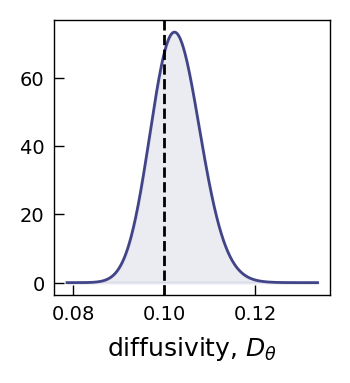

In [27]:
lnDtheta_map = lambda_map[1]
lnDtheta_err = np.sqrt(lambda_cov[1,1])
print(f'z-score: {(lnDtheta_map-np.log(Dtheta))/lnDtheta_err:.5}')

lnx = np.linspace(lnDtheta_map-5*lnDtheta_err, lnDtheta_map+5*lnDtheta_err, 500)
x = np.exp(lnx)
pdf = stats.lognorm.pdf(x, s=lnDtheta_err, scale=np.exp(lnDtheta_map))

# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.plot(x,pdf,color=cmap(0.2), label='true', lw=1)
plt.fill_between(x,pdf,alpha=0.1,color=cmap(0.2))

plt.axvline(x=Dtheta, color='k', ls='--', lw=1, label='True value')

# Set axis labels with font size 9 pt
ax.set_xlabel(r'diffusivity, $D_\theta$', fontsize=9)
# ax.set_xscale('log')

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/SP_Diffusivity.pdf')

z-score: 1.654


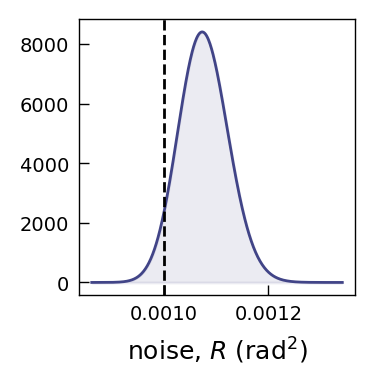

In [28]:
lnR_map = lambda_map[2]
lnR_err = np.sqrt(lambda_cov[2,2])
print(f'z-score: {(lnR_map-np.log(R))/lnR_err:.5}')

lnx = np.linspace(lnR_map-5*lnR_err, lnR_map+5*lnR_err, 500)
x = np.exp(lnx)
pdf = stats.lognorm.pdf(x, s=lnR_err, scale=np.exp(lnR_map))

# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.plot(x,pdf,color=cmap(0.2), label='true', lw=1)
plt.fill_between(x,pdf,alpha=0.1,color=cmap(0.2))

plt.axvline(x=R, color='k', ls='--', lw=1, label='True value')

# Set axis labels with font size 9 pt
ax.set_xlabel(r'noise, $R$ (rad$^2$)', fontsize=9)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/SP_Noise.pdf')

### Gradient-based optimizer

\begin{equation}
    \nabla_\lambda \log p(y\mid \lambda) = \mathbb{E}[\nabla_\lambda \ell_c(\lambda; \theta, y) \mid y,\lambda]
\end{equation}

Complete-data log likelihood $\ell_c(\lambda; \theta, y) = \ln p(\theta, y\mid \lambda)$ is given by 

$$ \ell_c(\lambda; \theta, y)  = \text{const.} - \tfrac{1}{2} (N-1) \ln D_\theta - \frac{1}{4 D_\theta \Delta t} \sum_{k=2}^{N} (\theta_{k} - \theta_{k-1} - \omega \Delta t)^2 - \tfrac{1}{2} N \ln R - \frac{1}{2 R} \sum_{k=1}^N (y_k - \theta_{k})^2 $$

In [29]:
Hk, ck, kalman_phases = SPNM.freeze_linearization(lambda_map, data, state_priors)

In [30]:
eps = 1e-7
g_log_fd = approx_fprime(lambda_map, lambda x: SPNM.neg_log_posterior_frozen(x, data, priors, Hk, ck), epsilon=eps)
g_log_an = SPNM.grad_neg_log_posterior_frozen(lambda_map, data, priors, Hk, ck)
print(g_log_fd)
print(g_log_an)

[-4.48550054  2.07295671 -2.01145667]
[-4.48553146  2.07299583 -2.01150932]


In [31]:
%%time

res = minimize(
    fun=lambda x: SPNM.neg_log_posterior_frozen(x, data, priors, Hk, ck),
    x0=(omega, np.log(Dtheta), np.log(R)),
    jac=lambda x: SPNM.grad_neg_log_posterior_frozen(x, data, priors, Hk, ck),
    method="L-BFGS-B"
)

lambda_map2 = res.x
print(res,'\n')

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: -2793.537926811043
        x: [ 1.045e+00 -2.284e+00 -6.830e+00]
      nit: 5
      jac: [-4.375e-05  1.479e-03 -1.743e-03]
     nfev: 7
     njev: 7
 hess_inv: <3x3 LbfgsInvHessProduct with dtype=float64> 

CPU times: user 192 ms, sys: 13.6 ms, total: 206 ms
Wall time: 251 ms


Compare to previous solution. They are close but need not be exactly the same.

In [32]:
print(lambda_map)
print(lambda_map2)
print(lambda_map - lambda_map2)

[ 1.02640295 -2.2772897  -6.83481449]
[ 1.04475635 -2.28391195 -6.83022897]
[-0.0183534   0.00662225 -0.00458551]


Compare to numerical derivative.

In [33]:
eps = 1e-7
g_log_fd = approx_fprime(lambda_map2, lambda x: SPNM.neg_log_posterior_frozen(x, data, priors,  Hk, ck), epsilon=eps)
g_log_an = SPNM.grad_neg_log_posterior_frozen(lambda_map2, data, priors, Hk, ck)
print(g_log_fd)
print(g_log_an)

[-5.00222086e-05  1.45973900e-03 -1.70985003e-03]
[-4.37479923e-05  1.47942529e-03 -1.74317229e-03]


## Expectation Maximization (EM) Algorithm


### Iterate to find MAP estimates

In [34]:
%%time 

guess = [omega, np.log(Dtheta), np.log(R)]
lambda_iter = SPNM.em_map_parameters(guess, data, priors, 
                                     max_iter=500, tol=1e-6, verbose=True, 
                                     print_every=10, param_mode="log")

iter	omega		lnDtheta	lnR
1	1.04472e+00	-2.27976e+00	-6.86580e+00
10	1.04476e+00	-2.28393e+00	-6.83008e+00

Converged at iteration 15 (max relative change = 5.82e-07)
CPU times: user 353 ms, sys: 21.5 ms, total: 375 ms
Wall time: 416 ms


In [35]:
print(lambda_map)
print(lambda_map2)

lambda_map3 = lambda_iter[-1,:]
print(lambda_iter[-1,:])

[ 1.02640295 -2.2772897  -6.83481449]
[ 1.04475635 -2.28391195 -6.83022897]
[ 1.04475588 -2.28396366 -6.83000093]


### Convergence


RMS error = 0.053189
Convergence rate = 0.65908


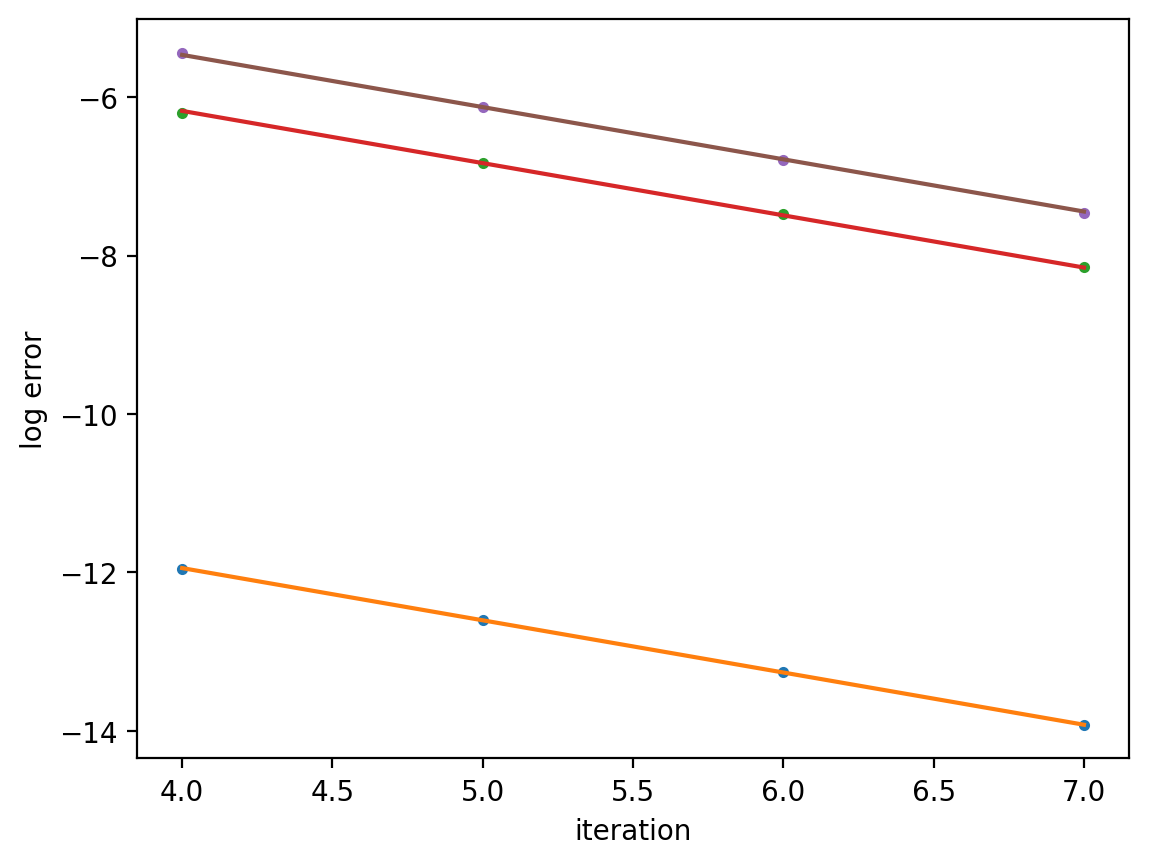

In [36]:
# Calculate convergence rate 
imin = 4
imax = 8
iN = imax-imin
y = np.concatenate(( np.log(np.abs(lambda_iter[imin:imax,0] - lambda_iter[-1,0])),
                     np.log(np.abs(lambda_iter[imin:imax,1] - lambda_iter[-1,1])),
                     np.log(np.abs(lambda_iter[imin:imax,2] - lambda_iter[-1,2])) ))
x = np.arange(imin,imax)

DM = np.concatenate(( np.column_stack(( x**0,  0*x,  0*x, -x)),
                      np.column_stack((  0*x, x**0,  0*x, -x)),
                      np.column_stack((  0*x,  0*x, x**0, -x)) ))
coeff = np.linalg.lstsq(DM, y, rcond=None)[0]
fit = DM@coeff

for i in range(3):
    plt.plot(x,y[i*iN:(i+1)*iN],'.')
    plt.plot(x,fit[i*iN:(i+1)*iN])
plt.xlabel('iteration')
plt.ylabel('log error')

error = np.sqrt(np.sum((fit - y)**2))
print('RMS error = %f'%error)

rate = coeff[-1]
print(f'Convergence rate = {rate:.5f}')

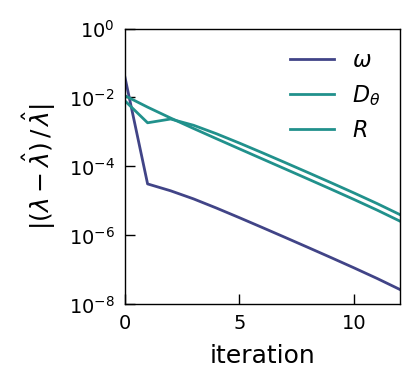

In [37]:
# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.8
right_margin = 0.2
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
ax.semilogy(np.abs((lambda_iter[:,0]-lambda_map3[0])/lambda_map3[0]), label=r'$\omega$', color=cmap(0.2), lw=1)
ax.semilogy(np.abs((lambda_iter[:,1]-lambda_map3[1])/lambda_map3[1]), label=r'$D_\theta$', color=cmap(0.5), lw=1)
ax.semilogy(np.abs((lambda_iter[:,2]-lambda_map3[2])/lambda_map3[2]), label=r'$R$', color=cmap(0.5), lw=1)
# ax.plot(x+jmin, 0.3*np.exp(fit[:jN])/np.abs(lambda_hat[0]), 'k--', lw=1)

# Set axis labels with font size 9 pt
ax.set_xlabel(r'iteration', fontsize=9)
ax.set_ylabel(r'$| (\lambda - \hat{\lambda}) \, / \, \hat{\lambda}|$', fontsize=9)
plt.ylim(1e-8,1)
plt.xlim(0,12)

# Create legend (frame turned off)
ax.legend(frameon=False, fontsize=8)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/SyntheticPhaseConvergence.pdf')

## Uncertainty Estimate

### Prior Information Matrix, $\mathcal{I}_{\text{prior}}=-\nabla_\lambda^2 \ln p(\lambda)\rvert_{\hat{\lambda}}$


In [38]:
I_prior = SPNM.prior_information(lambda_map2, priors, param_type="log")
print(I_prior)

[[1.         0.         0.        ]
 [0.         1.96300025 0.        ]
 [0.         0.         1.85080536]]


### Complete-data Information, $\mathcal{I}_{\text{comp}} = -\mathbb{E}[\nabla_\lambda^2 \ell_c(\lambda;\theta,y)\mid y, \hat{\lambda}]$ 

In [39]:
statistics = SPNM.smoothing_statistics_frozen(lambda_map2, data, priors, Hk, ck, param_type="log")
I_comp = SPNM.complete_data_information_frozen(statistics, param_type="log")
print(I_comp)

[[2.45129656e+02 4.48001003e-02 0.00000000e+00]
 [4.48001003e-02 4.99535520e+02 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 1.00015094e+03]]


### Missing Information, $\mathcal{I}_{\text{miss}} = \mathrm{Cov}(\nabla_\lambda \ell_c(\lambda; \theta, y)\mid y, \hat{\lambda})$ 

In [40]:
I_miss = SPNM.missing_information_frozen(statistics, priors, param_type="log")
print(I_miss)

[[ 3.35050714e-02 -1.00644462e-01  1.26435798e-01]
 [-1.00644462e-01  1.40720402e+02 -5.98173423e+01]
 [ 1.26435798e-01 -5.98173423e+01  4.78567175e+02]]


### Posterior Coviarance

In [41]:
%time 

res = SPNM.posterior_information_frozen(lambda_map2, data, priors,  Hk, ck, param_type="log")
print(np.linalg.norm(res['I_prior'] - I_prior))
print(np.linalg.norm(res['I_comp'] - I_comp))
print(np.linalg.norm(res['I_miss'] - I_miss))

CPU times: user 2 μs, sys: 1 μs, total: 3 μs
Wall time: 4.77 μs
0.0
0.0
0.0


In [42]:
lambda_cov2 = np.linalg.inv(I_prior + I_comp - I_miss)
print(np.linalg.norm(res['cov'] - lambda_cov2))

0.0


Compare to numerical result.  These are similar but not identical, as they describe different quantities.

In [43]:
print(np.linalg.norm(res['cov'] - lambda_cov))
print(np.linalg.eigvals(lambda_cov))
print(np.linalg.eigvals(res['cov']))

0.0006088469487813522
[0.00346289 0.00290937 0.00184178]
[0.00406346 0.00293127 0.0018414 ]


### EM Convergence rate

In [44]:
rho = np.max(np.linalg.eigvals(I_miss@np.linalg.inv(I_prior + I_comp)))
print(res['rho'] - rho)
print(f'Estimate of convergence rate = {-np.log(rho):.5f}')
print(f'EM convergence rate = {rate:.5f}')

0.0
Estimate of convergence rate = 0.67567
EM convergence rate = 0.65908
